TokaMaker Example: Analytic spheromak equilibrium {#doc_tMaker_fixed_ex4}
==========
In this example we show how to compute a simple spheromak equilibrium using TokaMaker and compare it to the corresponding analytic solution. This case is one of the verification tests used for TokaMaker (see section 4.1.1 of the [TokaMaker paper](https://doi.org/10.1016/j.cpc.2024.109111)) and demonstrates:
 1. Setting up a fixed-boundary equilibrium in a domain that includes the geometric axis ($R=0$)
 2. Defining $F*F'$ and $P'$ profiles directly
 3. Assessing the accuracy of the solution by comparison to the analytic result

### Analytic spheromak solution
For a plasma whose boundary is specified and includes the geometric axis, with no externally applied magnetic fields (toroidal or poloidal), zero pressure ($\partial P / \partial \psi = 0$), and $\partial F^2 / \partial \psi \propto \psi$, the Grad-Shafranov equation becomes the eigenvalue equation

$$
\Delta^* \psi = - \lambda^2 \psi
$$

The lowest-eigenvalue solution to this equation is the spheromak, which in a cylindrical domain $R \in [0,a]$, $Z \in [0,h]$ can be expressed analytically as

$$
\psi(R,Z) = \psi_0 \frac{\gamma_{1,1} R J_1(\gamma_{1,1} R)}{\chi_{0,1} J_1(\chi_{0,1})} \sin \left( \frac{\pi Z}{h} \right),
$$

where $\gamma_{1,1} = \chi_{1,1} / a$, $\chi_{i,1}$ is the first zero of the i-th Bessel function $J_i$, and the eigenvalue is given by $\lambda^2 = \gamma_{1,1}^2 + (\pi/h)^2$. The normalization is chosen such that the maximum value of $\psi$ is $\psi_0$.

In [1]:
import os
import sys
import numpy as np
from scipy.special import jv, jn_zeros
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(6,6)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

## Load TokaMaker library

To load the TokaMaker python module we need to tell python where to the module is located. This can be done either through the `PYTHONPATH` environment variable or using within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` on macOS).

For meshing we will use the \ref OpenFUSIONToolkit.TokaMaker.gs_Domain "gs_Domain" class to build a 2D triangular grid suitable for Grad-Shafranov equilibria. This class uses the [triangle code](https://www.cs.cmu.edu/~quake/triangle.html) through a simple internal python wrapper within OFT.

In [2]:
tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.TokaMaker import TokaMaker
from OpenFUSIONToolkit.TokaMaker.meshing import gs_Domain

## Define analytic solution
We first define a function to evaluate the analytic spheromak solution above at a set of points for a domain of radius `a` and height `h`, which will be used to compare to the TokaMaker solution below. The zeros of the Bessel functions are computed using `scipy.special.jn_zeros`.

In [3]:
def spheromak_psi(r,z,a,h):
    r'''! Evaluate analytic spheromak flux (with \f$\psi_0 = 1\f$)

    @param r Radial positions
    @param z Vertical positions
    @param a Radius of domain
    @param h Height of domain
    @result \f$\psi(R,Z)\f$
    '''
    gamma_11 = jn_zeros(1,1)[0]/a
    chi_01 = jn_zeros(0,1)[0]
    return gamma_11*r*jv(1,gamma_11*r)*np.sin(np.pi*z/h)/(chi_01*jv(1,chi_01))

# Domain size
a = 1.0
h = 1.0
# Analytic eigenvalue
lam_sq = (jn_zeros(1,1)[0]/a)**2 + (np.pi/h)**2
print('Analytic eigenvalue: lambda^2 = {0:.6f}'.format(lam_sq))

Analytic eigenvalue: lambda^2 = 24.551575


## Create mesh
First we define a target size to set the resolution in our grid. This variable will be used later and represent the target edge size within our mesh, where units are in meters. In this case we use a modest resolution of 5 cm, which gives about 20 cells in each direction.

### Define regions and attributes
We now create the mesh object and define the various logical mesh regions. In this case we only have one region, which is named `plasma` and is of type `plasma`. See other examples for more complex cases with other region types.

In [4]:
mesh_dx = 0.05
# Create a G-S domain
gs_mesh = gs_Domain()
# Define region information for mesh
gs_mesh.define_region('plasma',mesh_dx,'plasma')

### Define geometry for region boundaries
Once the region types and properties are defined we now define the geometry of the mesh using shapes and references to the defined regions. In this case the domain is a simple rectangle of width `a` and height `h`, which is defined by its center point (R,Z) along with its width (W) and height (H) using \ref OpenFUSIONToolkit.TokaMaker.gs_Domain.add_rectangle "add_rectangle". Note that the inner edge of this rectangle lies on the geometric axis ($R=0$), where $\psi = 0$ by definition.

In [5]:
gs_mesh.add_rectangle(a/2.0,h/2.0,a,h,'plasma')

### Generate mesh
Now we generate the actual mesh using the \ref OpenFUSIONToolkit.TokaMaker.gs_Domain.build_mesh "build_mesh" method. This step may take a few moments as [triangle](https://www.cs.cmu.edu/~quake/triangle.html) generates the mesh.

Note that, as is common with unstructured meshes, the mesh is stored a list of points `mesh_pts` of size (np,2), a list of cells formed from three points each `mesh_lc` of size (nc,3), and an array providing a region id number for each cell `mesh_reg` of size (nc,).

In [6]:
mesh_pts, mesh_lc, mesh_reg = gs_mesh.build_mesh()

Assembling regions:
  # of unique points    = 80
  # of unique segments  = 4
Generating mesh with Triangle:
  # of points  = 662
  # of cells   = 1242
  # of regions = 1


### Plot resulting regions and grid
We now plot the mesh to inspect proper generation.

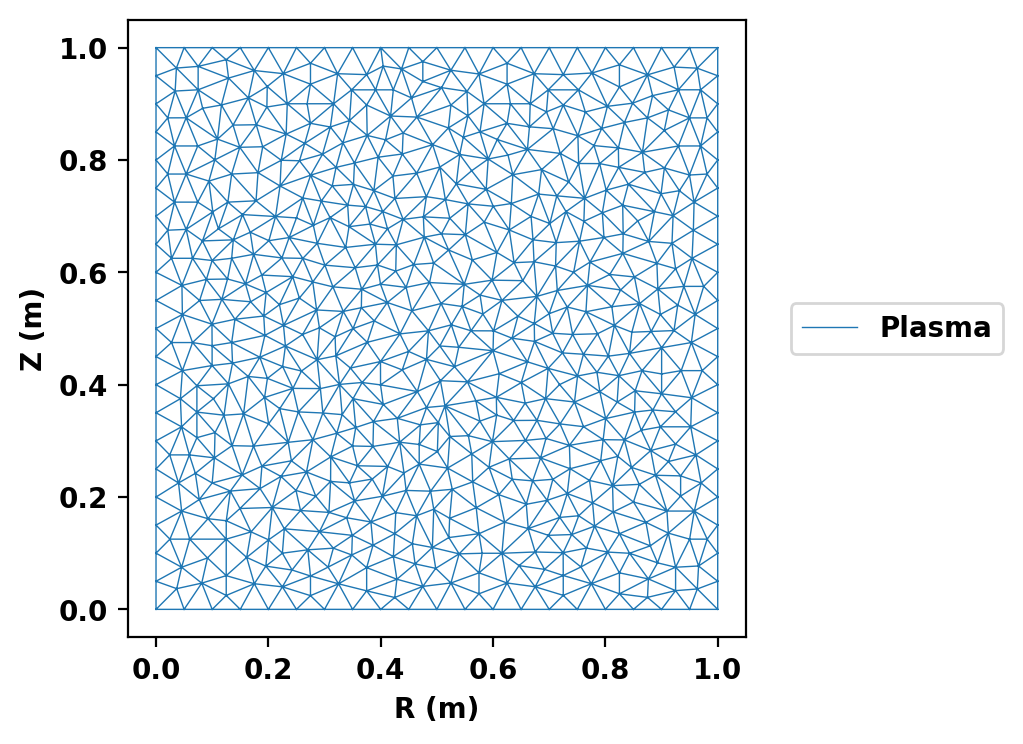

In [7]:
fig, ax = plt.subplots(1,1,figsize=(5,5),constrained_layout=True)
gs_mesh.plot_mesh(fig,ax)

## Compute equilibrium

### Initialize TokaMaker object
We now create a \ref OpenFUSIONToolkit.OFT_env "OFT_env" instance for execution using two threads and a \ref OpenFUSIONToolkit.TokaMaker.TokaMaker "TokaMaker" instance to use for equilibrium calculations. Note at present only a single `TokaMaker` instance can be used per python kernel, so this command should only be called **once** in a given Jupyter notebook or python script. In the future this restriction may be relaxed.

In [8]:
myOFT = OFT_env(nthreads=2)
mygs = TokaMaker(myOFT)

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/



Base release:        v26.9
Development branch:  HEAD_detached_at_7caa53b2
Revision id:         7caa53b2

Parallelization Info:
  # of MPI tasks      =    1
  # of NUMA nodes     =    1
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------



### Load mesh into TokaMaker
Now we load the mesh generated above using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup_mesh "setup_mesh" and set the code to operate in fixed boundary mode by setting the `free_boundary` setting to False. Finally, we call \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.setup "setup" to setup the required solver objects. During this call we specify the desired element order (min=2, max=4). As a spheromak has no externally applied toroidal field we leave `F0` at its default value of zero.

In [9]:
mygs.setup_mesh(mesh_pts,mesh_lc)
mygs.settings.free_boundary = False
mygs.setup(order=2)


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.000E+00
    # of points  =     662
    # of edges   =    1903
    # of cells   =    1242
    # of boundary points =      80
    # of boundary edges  =      80
    # of boundary cells  =      80
  Resolution statistics:
    hmin =  3.125E-02
    hrms =  4.530E-02
    hmax =  7.416E-02
  Surface grounded at vertex      21


**** Creating Lagrange FE space
  Order  =    2
  Minlev =   -1



### Define flux profiles
To recover the spheromak solution we need $P' = 0$ and $F*F' \propto \psi$. The pressure contribution is removed by setting the pressure scale factor `p_scale` to zero (the shape of the $P'$ profile then has no effect, so we simply use a `flat` profile). For $F*F'$ we use a `linterp` profile, which defines the profile as a piecewise linear function of the normalized poloidal flux $\hat{\psi}$, that goes from one on the magnetic axis ($\hat{\psi}=0$) to zero at the boundary ($\hat{\psi}=1$). As $\psi=0$ on the boundary of the domain, $1-\hat{\psi} = \psi/\psi_0$ so this profile is linear in $\psi$ as required.

As this is a linear eigenvalue problem the amplitude of the solution ($\psi_0$) is arbitrary, so we do not set any global targets (eg. `Ip`) and instead normalize the solution when comparing to the analytic result below.

In [10]:
mygs.p_scale = 0.0
ffp_prof = {
    'type': 'linterp',
    'x': [0.0,1.0],
    'y': [1.0,0.0]
}
mygs.set_profiles(ffp_prof=ffp_prof,pp_prof={'type': 'flat'})

### Update solver settings
To allow accurate comparison with the analytic solution we tighten the nonlinear convergence tolerance (`nl_tol`) well below its default value and increase the maximum number of iterations (`maxits`) accordingly. We also disable under-relaxation of the nonlinear iteration (`urf`), which is not needed for this simple case. After modifying settings we must call \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.update_settings "update_settings" to pass the new values to TokaMaker.

In [11]:
mygs.settings.nl_tol = 1.E-12
mygs.settings.maxits = 100
mygs.settings.urf = 0.0
mygs.update_settings()

### Compute equilibrium
Now we initialize the flux function using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.init_psi "init_psi", which by default uses a uniform current over the full plasma domain, and compute the equilibrium using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.solve "solve".

In [12]:
mygs.init_psi()
_ = mygs.solve()

Starting non-linear GS solver
     1  2.1643E+00  0.0000E+00  4.8437E-01  6.4552E-01  4.9997E-01  0.0000E+00
     2  1.0261E+01  0.0000E+00  3.9689E-01  6.3417E-01  4.9996E-01  0.0000E+00
     3  2.2445E+01  0.0000E+00  2.7339E-01  6.3006E-01  4.9997E-01  0.0000E+00


     4  3.3217E+01  0.0000E+00  1.6347E-01  6.2854E-01  4.9998E-01  0.0000E+00
     5  4.0407E+01  0.0000E+00  8.9750E-02  6.2795E-01  4.9998E-01  0.0000E+00
     6  4.4561E+01  0.0000E+00  4.7055E-02  6.2771E-01  4.9998E-01  0.0000E+00
     7  4.6793E+01  0.0000E+00  2.4089E-02  6.2762E-01  4.9998E-01  0.0000E+00
     8  4.7949E+01  0.0000E+00  1.2184E-02  6.2758E-01  4.9998E-01  0.0000E+00
     9  4.8537E+01  0.0000E+00  6.1258E-03  6.2756E-01  4.9998E-01  0.0000E+00
    10  4.8833E+01  0.0000E+00  3.0707E-03  6.2756E-01  4.9998E-01  0.0000E+00
    11  4.8982E+01  0.0000E+00  1.5370E-03  6.2755E-01  4.9998E-01  0.0000E+00
    12  4.9057E+01  0.0000E+00  7.6883E-04  6.2755E-01  4.9998E-01  0.0000E+00
    13  4.9094E+01  0.0000E+00  3.8445E-04  6.2755E-01  4.9998E-01  0.0000E+00
    14  4.9112E+01  0.0000E+00  1.9221E-04  6.2755E-01  4.9998E-01  0.0000E+00
    15  4.9122E+01  0.0000E+00  9.6096E-05  6.2755E-01  4.9998E-01  0.0000E+00
    16  4.9126E+01  0.0000E+00  4.8042E-05  6.2755E-

    22  4.9131E+01  0.0000E+00  7.5027E-07  6.2755E-01  4.9998E-01  0.0000E+00
    23  4.9131E+01  0.0000E+00  3.7512E-07  6.2755E-01  4.9998E-01  0.0000E+00
    24  4.9131E+01  0.0000E+00  1.8755E-07  6.2755E-01  4.9998E-01  0.0000E+00
    25  4.9131E+01  0.0000E+00  9.3773E-08  6.2755E-01  4.9998E-01  0.0000E+00
    26  4.9131E+01  0.0000E+00  4.6885E-08  6.2755E-01  4.9998E-01  0.0000E+00
    27  4.9131E+01  0.0000E+00  2.3442E-08  6.2755E-01  4.9998E-01  0.0000E+00
    28  4.9131E+01  0.0000E+00  1.1721E-08  6.2755E-01  4.9998E-01  0.0000E+00
    29  4.9131E+01  0.0000E+00  5.8603E-09  6.2755E-01  4.9998E-01  0.0000E+00
    30  4.9131E+01  0.0000E+00  2.9301E-09  6.2755E-01  4.9998E-01  0.0000E+00
    31  4.9131E+01  0.0000E+00  1.4650E-09  6.2755E-01  4.9998E-01  0.0000E+00
    32  4.9131E+01  0.0000E+00  7.3252E-10  6.2755E-01  4.9998E-01  0.0000E+00
    33  4.9131E+01  0.0000E+00  3.6626E-10  6.2755E-01  4.9998E-01  0.0000E+00
    34  4.9131E+01  0.0000E+00  1.8313E-10  6.2755E-

### Print information and plot equilibrium
After computing the equilibrium, basic parameters can be displayed using the \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.print_info "print_info" method and flux surfaces can be plotted using the \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.plot_psi "plot_psi" method. Note that as there is no applied toroidal field the toroidal field in the spheromak is generated entirely by poloidal currents in the plasma.

Equilibrium Statistics:
  Topology                =   Limited
  Toroidal Current [A]    =    1.3983E+07
  Current Centroid [m]    =    0.490  0.500
  Magnetic Axis [m]       =    0.628  0.500
  Elongation              =    1.039 (U:  1.039, L:  1.039)
  Triangularity           =   -0.270 (U: -0.270, L: -0.270)
  Plasma Volume [m^3]     =    3.142
  q_0, q_95               =    0.653  0.433
  Plasma Pressure [Pa]    =   Axis:  0.0000E+00, Peak:  0.0000E+00
  Stored Energy [J]       =    0.0000E+00
  <Beta_pol> [%]          =    0.0000
  Diamagnetic flux [Wb]   =    3.5463E+00
  Toroidal flux [Wb]      =    3.5463E+00
  l_i                     =    0.8064


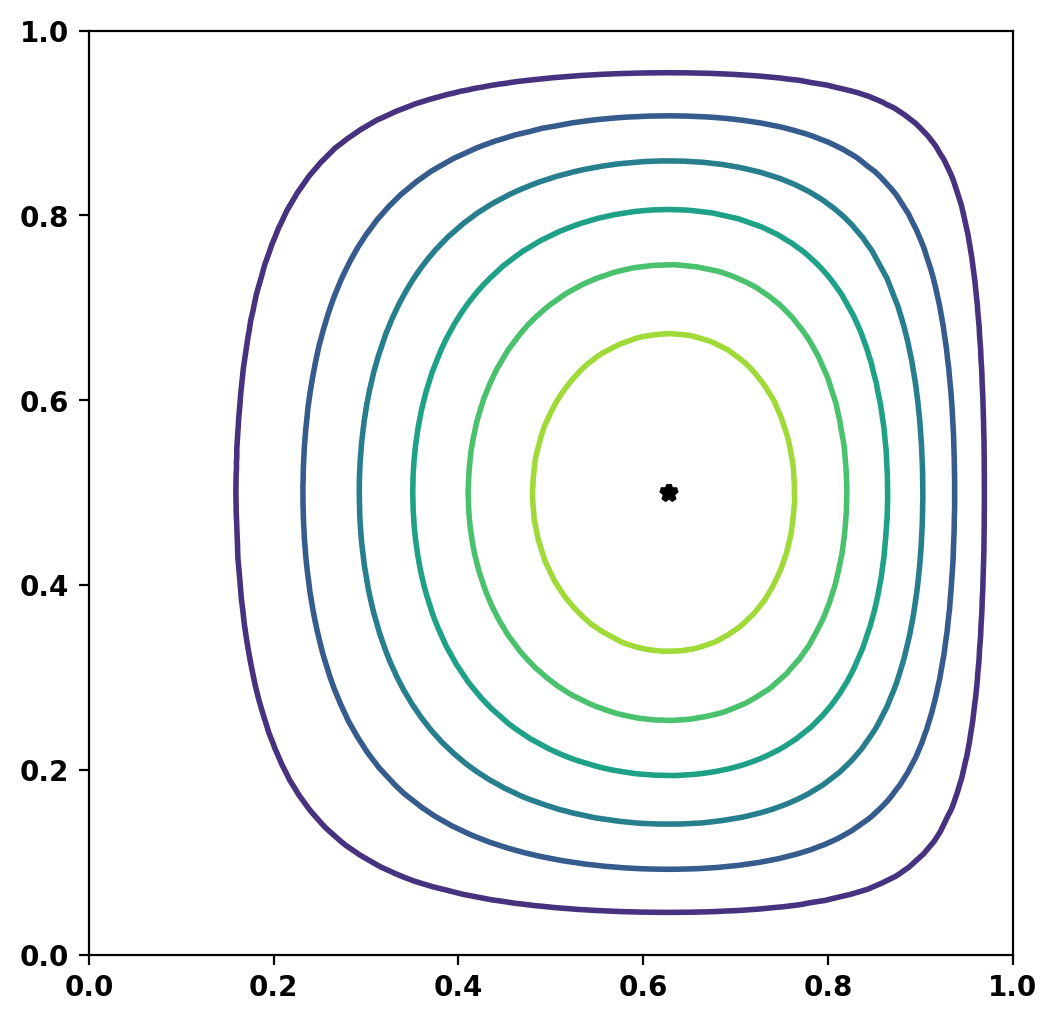

In [13]:
mygs.print_info()
# Plot flux surfaces
fig, ax = plt.subplots(1,1)
mygs.plot_psi(fig,ax)

## Compare to analytic solution

### Compute error in $\psi$
We now retrieve the (un-normalized) poloidal flux on the node points using \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.get_psi "get_psi" and evaluate the analytic solution at the same locations, which are available in `mygs.r`. As noted above the amplitude of the solution is arbitrary, so we scale the TokaMaker solution to best match the analytic solution in a least-squares sense before computing the relative error.

We can also check the eigenvalue itself. In TokaMaker the toroidal current source from the $F*F'$ term is $\frac{1}{2}$`ffp_scale`$\cdot (F*F')(\hat{\psi})/R$, so for this profile `ffp_scale`/2 should match $\lambda^2$ above. At this resolution the two agree to better than 0.1%.

In [14]:
psi_TM = mygs.get_psi(False)
psi_analytic = spheromak_psi(mygs.r[:,0],mygs.r[:,1],a,h)
psi_TM /= psi_TM.dot(psi_analytic)/psi_analytic.dot(psi_analytic)
psi_err = np.linalg.norm(psi_TM-psi_analytic)/np.linalg.norm(psi_analytic)
print('Relative error in psi = {0:.4E}'.format(psi_err))
print('Eigenvalue: TokaMaker = {0:.6f}, Analytic = {1:.6f}'.format(mygs.ffp_scale/2.0,lam_sq))

Relative error in psi = 2.0397E-05
Eigenvalue: TokaMaker = 24.565558, Analytic = 24.551575


### Plot comparison
Finally we plot the flux surfaces from the two solutions, which are indistinguishable at this scale, along with the spatial distribution of the error. Note that `mygs.lc` provides a triangulation of the node points in `mygs.r` suitable for plotting with matplotlib.

**Note:** If you change the mesh resolution (`mesh_dx`) or the finite element order (`order` in the call to `setup`) above and re-run this notebook, you should observe the error decrease with increasing resolution and/or order at the expected rate of $O(\Delta x^{p+1})$, where $p$ is the polynomial degree of the finite elements, as shown in Fig. 6 of the [TokaMaker paper](https://doi.org/10.1016/j.cpc.2024.109111).

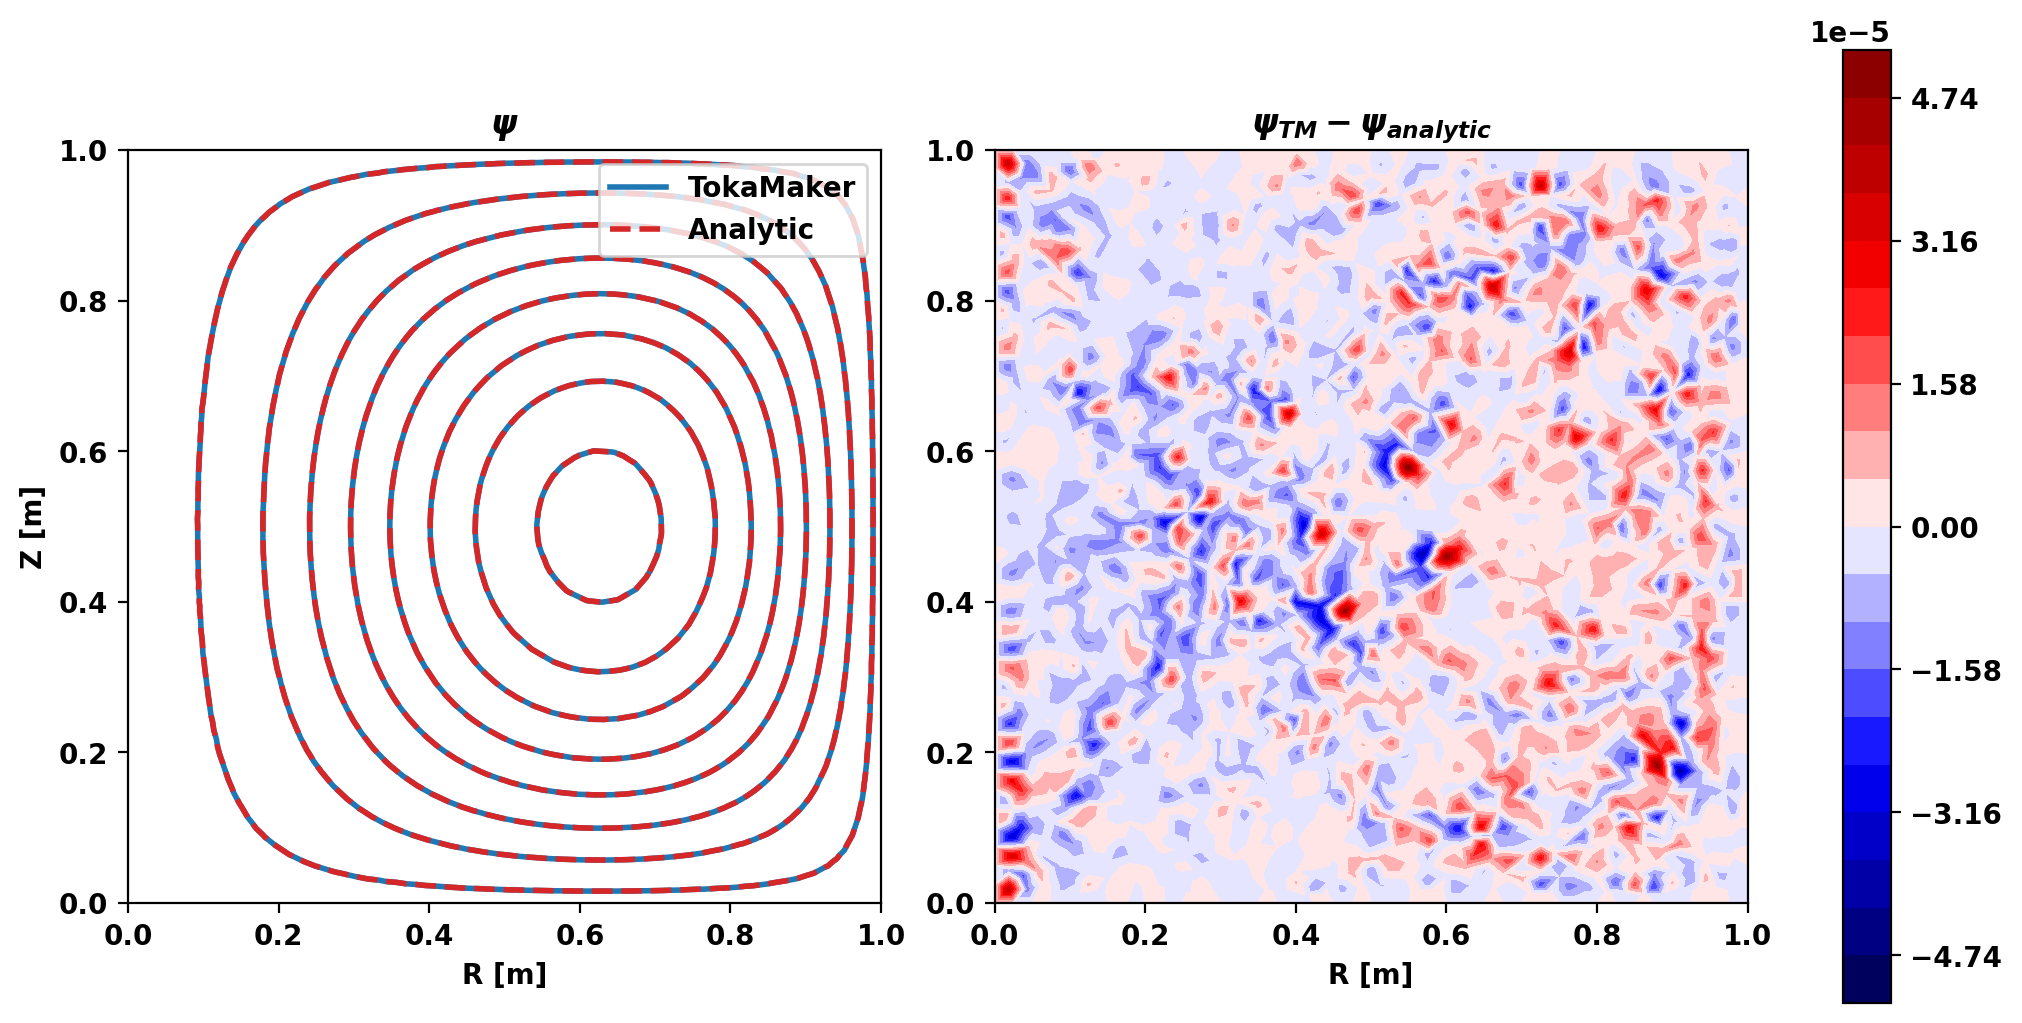

In [15]:
fig, ax = plt.subplots(1,2,figsize=(10,5),constrained_layout=True)
levels = np.linspace(0.05,0.95,8)
ax[0].tricontour(mygs.r[:,0],mygs.r[:,1],mygs.lc,psi_TM,levels=levels,colors='tab:blue')
ax[0].tricontour(mygs.r[:,0],mygs.r[:,1],mygs.lc,psi_analytic,levels=levels,colors='tab:red',linestyles='dashed')
ax[0].plot([],[],color='tab:blue',label='TokaMaker')
ax[0].plot([],[],color='tab:red',linestyle='dashed',label='Analytic')
ax[0].legend(loc='upper right')
ax[0].set_title(r'$\psi$')
psi_diff = psi_TM-psi_analytic
max_diff = abs(psi_diff).max()
clf = ax[1].tricontourf(mygs.r[:,0],mygs.r[:,1],mygs.lc,psi_diff,levels=np.linspace(-max_diff,max_diff,21),cmap='seismic')
ax[1].set_title(r'$\psi_{TM} - \psi_{analytic}$')
fig.colorbar(clf,ax=ax[1])
for ax_tmp in ax:
    ax_tmp.set_aspect('equal')
    ax_tmp.set_xlabel('R [m]')
_ = ax[0].set_ylabel('Z [m]')